# 04 · Test results: how the ensemble did on data it had never seen

## What this notebook shows

Notebooks 02 and 03 built the forecast and picked the final model (`ens_mean`, the plain
average of five models) using **2021 – 2024** only. This notebook shows how that final model
did on **2025-01-01 → 2026-09-24**, a period that was kept locked away until every choice was
made. It answers three questions:

1. How far off is the forecast on a normal day? (about **8 calls per division per day**)
2. Is it better than the simple rules it had to beat, and how sure are we?
3. Did it keep working after the late-2025 drop in first-responder calls?

**This notebook only reads saved results.** It never re-runs the test. The forecasts were
made and scored once, and the numbers below come from `reports/holdout_test.json` and
`data/processed/holdout_predictions_v2.parquet`.

### Glossary

| Term | Meaning |
|---|---|
| **Test set** | Data the models never saw while being built. Used once, at the very end, as an honest exam. |
| **MAE** (mean absolute error) | The average size of a miss, ignoring whether we guessed too high or too low. MAE 8 = off by 8 calls on a typical day. Lower is better. |
| **Baseline** | A simple rule the models must beat. `same_wd_13w`: average of the same weekday over the last 13 weeks. `plain_28d`: average of the last 28 days. |
| **Confidence interval (CI)** | A range that shows how sure we are about a difference. If the whole range is below 0, the ensemble is clearly better; if it crosses 0, we can't be sure. |
| **Break** | 2025-12-20, when first-responder calls dropped sharply. We check the result before and after it. |

## Why the test is used only once

If you look at the test results, change something and test again, the test stops being
honest: you have tuned the model to the exam. So the project scored the test **one time**,
after the final model was frozen, and saved the results. Re-running it here would not change
the numbers, but it would break that promise, so this notebook only **reads** the saved files.

First, load the tools and point Python at the repo folder.

In [ ]:
import json
import os
from pathlib import Path
from typing import cast

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from ycit440_sim_forecast import evaluate
from ycit440_sim_forecast.holdout import BREAK_DATE

# VS Code and nbconvert start notebooks in notebooks/; every path below is relative
# to the repo root.
if not Path("pyproject.toml").exists():
    os.chdir(Path.cwd().parent)

Chart style and colours. The ensemble is always **blue**, the two baselines are **orange**
and **yellow**, and the five single models are grey.

In [ ]:
pl.Config.set_tbl_width_chars(140)
plt.rcParams.update(
    {
        "figure.dpi": 90,
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "axes.titlelocation": "left",
        "axes.titleweight": "bold",
        "legend.frameon": False,
        "font.size": 9,
    }
)
BASELINES = ["same_wd_13w", "plain_28d"]
COLOR = {"ens_mean": "#2a78d6", "same_wd_13w": "#eb6834", "plain_28d": "#eda100"}
GREY, ACTUAL = "#b5b4ad", "#0b0b0b"


def check(cond: bool, msg: str) -> None:
    """Stop the notebook when a number does not match what we expect."""
    if not cond:
        raise AssertionError(msg)

## Load the saved results

Two files: the **report** (all the summary numbers) and the **forecasts** themselves, one row
per model, per day, per division, with the actual count (`y_true`) next to the forecast
(`y_pred`).

In [ ]:
report = json.loads(Path("reports/holdout_test.json").read_text())
preds = pl.read_parquet("data/processed/holdout_predictions_v2.parquet")
period = report["period"]
print(f"Test period: {period['start']} to {period['end']}")
print(f"Final model: {report['final_model']}")
print(f"{preds.height:,} saved forecasts from {preds['model'].n_unique()} models")

Test period: 2025-01-01 to 2026-09-24
Final model: ens_mean
30,336 saved forecasts from 8 models


## The headline: average miss per model

The table lists every model's **MAE** over the whole test, best first. `bias` says whether a
model tends to guess too high (positive) or too low (negative); values near 0 mean no
systematic lean.

In [ ]:
kind = {"ens_mean": "final ensemble"} | dict.fromkeys(BASELINES, "baseline")
overall = (
    pl.DataFrame(report["overall"])
    .select("model", "mae", "bias")
    .with_columns(kind=pl.col("model").replace_strict(kind, default="single model"))
    .sort("mae")
)
overall

model,mae,bias,kind
str,f64,f64,str
"""ens_mean""",7.998,-0.215,"""final ensemble"""
"""cat_tweedie""",8.118,-0.127,"""single model"""
"""ets_weekly""",8.17,-0.643,"""single model"""
"""plain_28d""",8.202,0.123,"""baseline"""
"""topdown_ets""",8.239,-0.144,"""single model"""
"""lgbm_poisson""",8.36,0.052,"""single model"""
"""lgbm_poisson_raw""",8.477,-0.215,"""single model"""
"""same_wd_13w""",8.792,0.239,"""baseline"""


The same numbers as a chart. Bars start at 0 so the differences are shown at their true size:
the models are all close, and the gap between best and worst is under one call.

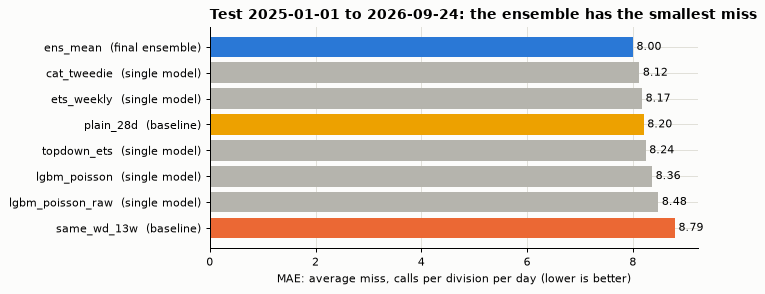

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.2))
labels = [f"{m}  ({k})" for m, k in overall.select("model", "kind").rows()]
colors = [COLOR.get(m, GREY) for m in overall["model"]]
bars = ax.barh(labels, overall["mae"], color=colors)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.invert_yaxis()
ax.set(xlabel="MAE: average miss, calls per division per day (lower is better)")
ax.set_title("Test 2025-01-01 to 2026-09-24: the ensemble has the smallest miss")
plt.show()

**How to read MAE.** `ens_mean` has an MAE of about **8.0**: on average the forecast is off by
about **8 calls per division per day**. To put that in context, here is how many calls a
division gets on an average test day.

In [ ]:
scored = preds.filter(pl.col("model") == "ens_mean", pl.col("y_true").is_not_null())
typical_day = scored["y_true"].mean()
ens_mae = overall.filter(pl.col("model") == "ens_mean")["mae"].item()
print(f"Average calls per division per day in the test: {typical_day:.1f}")
print(f"Average miss of ens_mean: {ens_mae:.2f} calls ({ens_mae / typical_day:.0%})")

Average calls per division per day in the test: 56.7
Average miss of ens_mean: 8.00 calls (14%)


## Before and after the break

On **2025-12-20** first-responder calls dropped sharply (see notebook 01). A model built on
the old pattern could fail after a change like that, so the test is split in two. The table
shows each model's MAE in each half.

In [ ]:
by_period = (
    pl.DataFrame(report["by_period"])
    .pivot("period", index="model", values="mae")
    .select("model", "before_break", "after_break")
    .sort("before_break")
)
by_period

model,before_break,after_break
str,f64,f64
"""ens_mean""",8.12,7.844
"""cat_tweedie""",8.164,8.06
"""plain_28d""",8.271,8.114
"""ets_weekly""",8.351,7.942
"""topdown_ets""",8.362,8.082
"""lgbm_poisson""",8.435,8.264
"""same_wd_13w""",8.568,9.075
"""lgbm_poisson_raw""",8.619,8.298


`ens_mean` has the lowest MAE in both halves, and it did a little *better* after the break
than before. The official baseline `same_wd_13w` got clearly worse after the break: it
averages the last 13 weeks, so it kept forecasting the old, higher level for a long time.
`plain_28d` only looks at the last 4 weeks, so it caught up with the drop quickly.

## How sure are we? (bootstrap confidence intervals)

A lower MAE could be luck: a few easy weeks can tilt the score. To check, the project
re-shuffled the test **2,000 times** in blocks of a week (a *bootstrap*) and recomputed the
difference each time. The **95% confidence interval** is the range that covers most of those
re-shuffled differences.

The difference is *ens_mean's MAE minus the other model's MAE*, so **negative means the
ensemble is better**. If the whole interval is below 0, the win is clear. If it crosses 0, the
win could be luck. The models compared are the two baselines and `lgbm_poisson_raw`, the best
single model on validation.

In [ ]:
order = {"test": 0, "before_break": 1, "after_break": 2}
rows = [
    {"period": name, **cmp}
    for name, refs in report["bootstrap"]["final"].items()
    for cmp in refs.values()
]
boot = (
    pl.DataFrame(rows)
    .select("period", "reference", "diff", "ci_low", "ci_high")
    .with_columns(clear_win=pl.col("ci_high") < 0)
    .sort(pl.col("period").replace_strict(order), "reference")
)
boot

period,reference,diff,ci_low,ci_high,clear_win
str,str,f64,f64,f64,bool
"""test""","""lgbm_poisson_raw""",-0.479,-0.752,-0.255,true
"""test""","""plain_28d""",-0.204,-0.428,0.031,false
"""test""","""same_wd_13w""",-0.794,-1.082,-0.497,true
"""before_break""","""lgbm_poisson_raw""",-0.499,-0.962,-0.149,true
"""before_break""","""plain_28d""",-0.151,-0.493,0.214,false
"""before_break""","""same_wd_13w""",-0.448,-0.835,-0.043,true
"""after_break""","""lgbm_poisson_raw""",-0.453,-0.691,-0.219,true
"""after_break""","""plain_28d""",-0.27,-0.519,-0.014,true
"""after_break""","""same_wd_13w""",-1.231,-1.607,-0.865,true


Each dot below is the difference; the line through it is the 95% interval. Blue = the whole
interval is below 0 (a clear win). Grey = the interval crosses 0 (not certain).

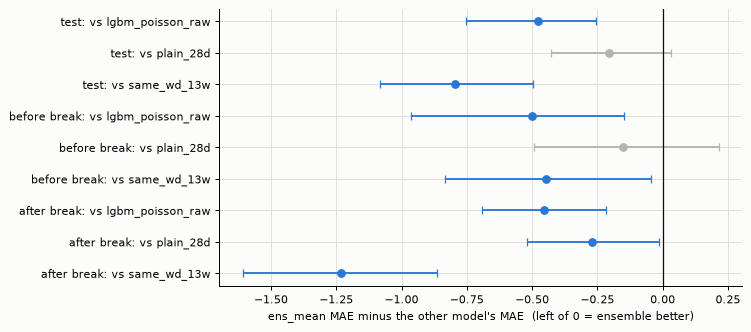

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for i, row in enumerate(boot.iter_rows(named=True)):
    color = COLOR["ens_mean"] if row["clear_win"] else GREY
    xerr = [[row["diff"] - row["ci_low"]], [row["ci_high"] - row["diff"]]]
    ax.errorbar(row["diff"], i, xerr=xerr, fmt="o", color=color, capsize=3)
pairs = boot.select("period", "reference").rows()
labels = [f"{p.replace('_', ' ')}: vs {r}" for p, r in pairs]
ax.set_yticks(range(boot.height), labels)
ax.axvline(0, color=ACTUAL, lw=1)
ax.invert_yaxis()
ax.set(xlabel="ens_mean MAE minus the other model's MAE  (left of 0 = ensemble better)")
plt.show()

**What this says, plainly.**

- **Against `same_wd_13w`** (the official baseline): the ensemble is clearly better over the
  whole test (about 0.8 calls less per day), and better in both halves (only just before the
  break: the interval ends at −0.04).
- **Against `lgbm_poisson_raw`** (the best single model on validation): clearly better in the
  whole test and in both halves. Averaging five models beat picking the single best one.
- **Against `plain_28d`** (the 28-day average): the ensemble is ahead by about 0.2 calls per
  day, but the interval runs from about −0.43 to **+0.03**, so it **crosses 0**. We cannot
  claim a certain win over this simple rule. Before the break the interval is about −0.49 to
  +0.21 (no clear difference); after the break it is −0.52 to −0.01, just below 0, so the
  ensemble was slightly but clearly better after the drop.

## Over time: forecasts against what actually happened

The chart below adds up the six divisions into a **city total** per day and compares the
actual count with `ens_mean` and the official baseline. Daily counts jump around a lot, so
every line is a **7-day rolling average** (each point is the average of that day and the six
before it). The dashed line marks the break.

This helper builds the 7-day lines for the whole city or for one division.

In [ ]:
SHOW = ["ens_mean", "same_wd_13w"]


def seven_day_view(division: int | None = None) -> pl.DataFrame:
    """Daily actual and forecast totals, smoothed with a 7-day rolling mean."""
    rows = preds.filter(pl.col("model").is_in(SHOW))
    if division is not None:
        rows = rows.filter(pl.col("DIVISION") == division)
    daily = rows.group_by("model", "target_start").agg(pl.col("y_true", "y_pred").sum())
    smooth = pl.col("y_true", "y_pred").rolling_mean(7).over("model")
    return daily.sort("target_start").with_columns(smooth)

And this one draws the chart: black is what actually happened, blue is the ensemble, orange
is the baseline.

In [ ]:
def plot_vs_actual(view: pl.DataFrame, title: str) -> None:
    """Plot the actual 7-day line against the forecasts, with the break marked."""
    _, ax = plt.subplots(figsize=(9, 3.4))
    actual = view.filter(pl.col("model") == SHOW[0])
    ax.plot(actual["target_start"], actual["y_true"], c=ACTUAL, lw=2, label="actual")
    for model in SHOW:
        part = view.filter(pl.col("model") == model)
        ax.plot(part["target_start"], part["y_pred"], color=COLOR[model], label=model)
    ax.axvline(
        float(mdates.date2num(BREAK_DATE)),
        color="#898781",
        ls="--",
        label=f"break ({BREAK_DATE})",
    )
    ax.set(title=title, ylabel="calls per day (7-day average)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=4)
    plt.show()

**City total.** Both forecasts follow the seasonal ups and downs. After the break the actual
line drops, and the ensemble follows it down faster than the 13-week baseline, which is still
averaging the older, higher weeks.

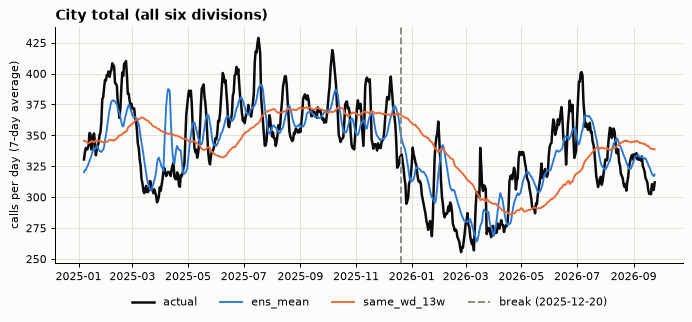

In [ ]:
plot_vs_actual(seven_day_view(), "City total (all six divisions)")

**One division.** The same chart for a single division. Change `DIVISION` to any number from
1 to 6 to look at another one.

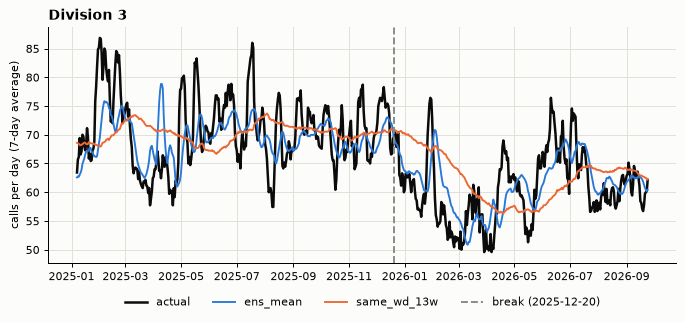

In [ ]:
DIVISION = 3
plot_vs_actual(seven_day_view(DIVISION), f"Division {DIVISION}")

## Month by month

The overall MAE is an average over 21 months. This chart shows the MAE of each month for the
ensemble and both baselines, so you can see whether the ensemble wins steadily or only in a
few months.

In [ ]:
three = ["ens_mean", *BASELINES]
monthly = (
    pl.DataFrame(report["by_year_month"])
    .filter(pl.col("model").is_in(three))
    .with_columns(month=(pl.col("year_month") + "-01").str.to_date())
    .sort("month")
)
wide = monthly.pivot("model", index="year_month", values="mae")
wins = wide.filter(pl.col("ens_mean") < pl.min_horizontal(*BASELINES)).height
print(f"ens_mean had the lowest MAE of the three in {wins} of {wide.height} months")

ens_mean had the lowest MAE of the three in 15 of 21 months


Each line is one model's average miss in each month. Lower is better.

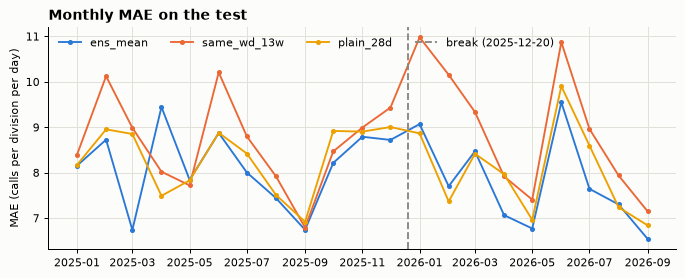

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.2))
for model in three:
    part = monthly.filter(pl.col("model") == model)
    ax.plot(part["month"], part["mae"], marker=".", color=COLOR[model], label=model)
ax.axvline(
    float(mdates.date2num(BREAK_DATE)),
    color="#898781",
    ls="--",
    label=f"break ({BREAK_DATE})",
)
ax.set(ylabel="MAE (calls per division per day)", title="Monthly MAE on the test")
ax.legend(ncols=4)
plt.show()

## How spread out are the misses?

MAE is the average size of a miss. The **standard deviation (SD)** of the errors says how
spread out the misses are: it is **the typical distance of a miss from the average miss**.
To get it, take each miss (forecast − actual), subtract the average miss (the bias),
square, average over all **n** forecasts (n is the number of division-days; we divide by
n, not n − 1) — that average is the **variance** — and take the square root.

The SD is bigger than the MAE because squaring makes a big miss count much more than a
small one: a handful of very unusual days (in the test, the worst was 2026-06-20 in
Division 1: 178 calls against a forecast of about 30) weigh far more in the SD than in the
MAE.

The table is computed straight from the saved test forecasts with `evaluate.error_spread`
(nothing is re-run), for the ensemble and both baselines, by division, plus "All".

In [ ]:
SPREAD_MODELS = ["ens_mean", *BASELINES]
test_rows = preds.filter(pl.col("model").is_in(SPREAD_MODELS))
spread = pl.concat(
    [
        evaluate.error_spread(test_rows, ["DIVISION"]).with_columns(
            pl.col("DIVISION").cast(pl.String)
        ),
        evaluate.error_spread(test_rows).with_columns(DIVISION=pl.lit("All")),
    ],
    how="diagonal",
)
saved = json.loads(Path("reports/error_spread.json").read_text())
saved_sd = next(
    r["error_sd"] for r in saved["test"]["overall"] if r["model"] == "ens_mean"
)
ens_sd = spread.filter(pl.col("DIVISION") == "All", pl.col("model") == "ens_mean")
check(round(ens_sd["error_sd"].item(), 3) == saved_sd, f"SD != report {saved_sd}")
print("Standard deviation (and variance) of the errors in the test, calls:")
(
    spread.with_columns(pl.col("error_sd", "error_var").round(2))
    .pivot("model", index="DIVISION", values=["error_sd", "error_var"])
    .select(
        "DIVISION",
        *(f"error_sd_{m}" for m in SPREAD_MODELS),
        *(f"error_var_{m}" for m in SPREAD_MODELS),
    )
)

Standard deviation (and variance) of the errors in the test, calls:


DIVISION,error_sd_ens_mean,error_sd_same_wd_13w,error_sd_plain_28d,error_var_ens_mean,error_var_same_wd_13w,error_var_plain_28d
str,f64,f64,f64,f64,f64,f64
"""1""",10.27,10.48,10.23,105.54,109.8,104.68
"""2""",10.88,11.62,11.02,118.29,135.11,121.39
"""3""",11.65,12.35,11.91,135.69,152.6,141.94
"""4""",10.52,11.28,10.43,110.76,127.14,108.82
"""5""",11.26,12.32,11.37,126.77,151.88,129.32
"""6""",10.71,12.27,11.25,114.6,150.51,126.61
"""All""",10.9,11.75,11.05,118.77,138.18,122.16


And the SD before and after the break (split on the forecast day, as above).

In [ ]:
(
    evaluate.error_spread(
        test_rows.with_columns(
            period=pl.when(pl.col("target_start") < BREAK_DATE)
            .then(pl.lit("before_break"))
            .otherwise(pl.lit("after_break"))
        ),
        ["period"],
    )
    .with_columns(pl.col("error_sd").round(2))
    .pivot("period", index="model", values="error_sd")
    .select("model", "before_break", "after_break")
    .sort(pl.col("model").replace_strict(SPREAD_MODELS, list(range(3))))
)

model,before_break,after_break
str,f64,f64
"""ens_mean""",10.66,11.17
"""same_wd_13w""",11.18,12.4
"""plain_28d""",10.75,11.42


**How to read this.** Over the whole test, `ens_mean` has the smallest spread (SD about
10.9 calls, against 11.1 for `plain_28d` and 11.8 for `same_wd_13w`). Division by division
the ensemble and `plain_28d` are very close (`plain_28d` is a hair tighter in Divisions 1
and 4), while `same_wd_13w` is the widest everywhere. Every model's misses spread out a
little more after the break, `same_wd_13w` the most. The test SDs (about 11) are well
below the validation ones (about 15) because the test has no event as extreme as the
April 2023 ice storm.

## Check: the numbers match the report

Last, recompute the ensemble's MAE straight from the saved forecasts (every row with a known
actual count) and confirm it matches the **7.998** in the report. If it did not, this cell
would stop the notebook with an error.

In [ ]:
mae = cast(float, (scored["y_true"] - scored["y_pred"]).abs().mean())
reported = next(r["mae"] for r in report["overall"] if r["model"] == "ens_mean")
check(round(mae, 3) == reported == 7.998, f"MAE {mae} != report {reported}")
print(f"ens_mean MAE from the forecasts: {mae:.3f}  (report: {reported})")

ens_mean MAE from the forecasts: 7.998  (report: 7.998)


## Summary

- On data it had never seen, the ensemble misses by about **8 calls per division per day**.
- It clearly beats the official baseline (`same_wd_13w`) and the best single model, before and
  after the late-2025 break.
- Its lead over the simple 28-day average (`plain_28d`) is small and **not certain** over the
  whole test; it is only clearly ahead after the break.

Notebook 05 runs the same ensemble on the latest data to make a real forecast.